<a href="https://colab.research.google.com/github/Sharaff-Ahamed/CN6005-Artificial-Intelligence/blob/main/WEEK2/week2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration 0: b0 = 0.0425, b1 = 0.1275, Cost = 10.8750
Iteration 100: b0 = 0.4454, b1 = 1.5483, Cost = 0.0541
Iteration 200: b0 = 0.3835, b1 = 1.5696, Cost = 0.0498
Iteration 300: b0 = 0.3301, b1 = 1.5877, Cost = 0.0466
Iteration 400: b0 = 0.2842, b1 = 1.6033, Cost = 0.0443
Iteration 500: b0 = 0.2447, b1 = 1.6168, Cost = 0.0425
Iteration 600: b0 = 0.2106, b1 = 1.6284, Cost = 0.0412
Iteration 700: b0 = 0.1813, b1 = 1.6383, Cost = 0.0403
Iteration 800: b0 = 0.1561, b1 = 1.6469, Cost = 0.0395
Iteration 900: b0 = 0.1344, b1 = 1.6543, Cost = 0.0390

Final coefficients: b0 = 0.1159, b1 = 1.6606


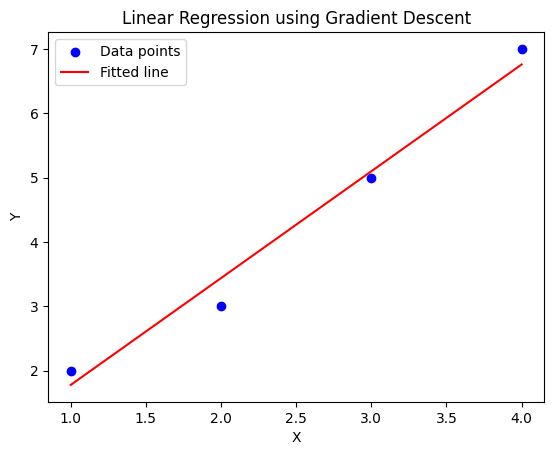

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Sample data (X and Y)
X = np.array([1, 2, 3, 4])
Y = np.array([2, 3, 5, 7])

# Initialize parameters
b0 = 0  # Intercept
b1 = 0  # Slope
learning_rate = 0.01  # Step size
iterations = 1000  # Number of iterations

# Number of samples
n = len(X)

# Gradient Descent function
def gradient_descent(X, Y, b0, b1, learning_rate, iterations):
    for i in range(iterations):
        # Predicted Y values (b0 + b1*X) using Linear Regression
        Y_pred = b0 + b1 * X

        # Compute gradients
        db0 = (1/n) * sum(Y_pred - Y)  # Partial derivative wrt b0
        db1 = (1/n) * sum((Y_pred - Y) * X)  # Partial derivative wrt b1

        # Update b0 and b1
        b0 -= learning_rate * db0
        b1 -= learning_rate * db1

        # Print values after every 100 iterations for insight
        if i % 100 == 0:
            cost = (1/(2*n)) * sum((Y_pred - Y)**2)
            print(f"Iteration {i}: b0 = {b0:.4f}, b1 = {b1:.4f}, Cost = {cost:.4f}")

    return b0, b1

# Run Gradient Descent
b0, b1 = gradient_descent(X, Y, b0, b1, learning_rate, iterations)

print(f"\nFinal coefficients: b0 = {b0:.4f}, b1 = {b1:.4f}")

# Plotting the result
plt.scatter(X, Y, color="blue", label="Data points")
plt.plot(X, b0 + b1 * X, color="red", label="Fitted line")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.title("Linear Regression using Gradient Descent")
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# For data loading and splitting
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

# For model training and evaluation
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# For scaling features
from sklearn.preprocessing import StandardScaler

In [ ]:
# Load the California Housing dataset from the local pre-loaded CSV inside Google Colab
try:
    # Load the training dataset from the local sample_data folder
    data = pd.read_csv('/content/sample_data/california_housing_train.csv')

    # Align column names to match standard fetch_california_housing nomenclature
    # Colab's CSV columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
    rename_dict = {
        'median_income': 'MedInc',
        'housing_median_age': 'HouseAge',
        'total_rooms': 'AveRooms',
        'total_bedrooms': 'AveBedrms',
        'population': 'Population',
        'households': 'AveOccup',
        'latitude': 'Latitude',
        'longitude': 'Longitude',
        'median_house_value': 'MedHouseVal'
    }
    data = data.rename(columns=rename_dict)

    # Colab's target is raw median_house_value (e.g., 452600.0). Standardize it by dividing by 100,000
    data['MedHouseVal'] = data['MedHouseVal'] / 100000.0

    # Reorder columns to match standard scikit-learn format
    data = data[['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']]

except Exception as e:
    print(f"Failed to load local dataset ({e}). Using standard sklearn fetch:")
    california = fetch_california_housing()
    data = pd.DataFrame(california.data, columns=california.feature_names)
    data['MedHouseVal'] = california.target

# Display the first ten rows
print(data.head(10))
data.count()

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  1.4936      15.0    5612.0     1283.0      1015.0     472.0     34.19   
1  1.8200      19.0    7650.0     1901.0      1129.0     463.0     34.40   
2  1.6509      17.0     720.0      174.0       333.0     117.0     33.69   
3  3.1917      14.0    1501.0      337.0       515.0     226.0     33.64   
4  1.9250      20.0    1454.0      326.0       624.0     262.0     33.57   
5  3.3438      29.0    1387.0      236.0       671.0     239.0     33.63   
6  2.6768      25.0    2907.0      680.0      1841.0     633.0     33.61   
7  1.7083      41.0     812.0      168.0       375.0     158.0     34.83   
8  2.1782      34.0    4789.0     1175.0      3134.0    1056.0     33.61   
9  2.1908      46.0    1497.0      309.0       787.0     271.0     34.83   

   Longitude  MedHouseVal  
0    -114.31        0.669  
1    -114.47        0.801  
2    -114.56        0.857  
3    -114.57        0.734  
4    -114.57        0.6

,0
MedInc,17000
HouseAge,17000
AveRooms,17000
AveBedrms,17000
Population,17000
AveOccup,17000
Latitude,17000
Longitude,17000
MedHouseVal,17000


In [ ]:
# Check for missing values
print(data.isnull().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [ ]:
# Statistical summary
print(data.describe())

             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  17000.000000  17000.000000  17000.000000  17000.000000  17000.000000   
mean       3.883578     28.589353   2643.664412    539.410824   1429.573941   
std        1.908157     12.586937   2179.947071    421.499452   1147.852959   
min        0.499900      1.000000      2.000000      1.000000      3.000000   
25%        2.566375     18.000000   1462.000000    297.000000    790.000000   
50%        3.544600     29.000000   2127.000000    434.000000   1167.000000   
75%        4.767000     37.000000   3151.250000    648.250000   1721.000000   
max       15.000100     52.000000  37937.000000   6445.000000  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  17000.000000  17000.000000  17000.000000  17000.000000  
mean     501.221941     35.625225   -119.562108      2.073009  
std      384.520841      2.137340      2.005166      1.159838  
min        1.000000     32.54000

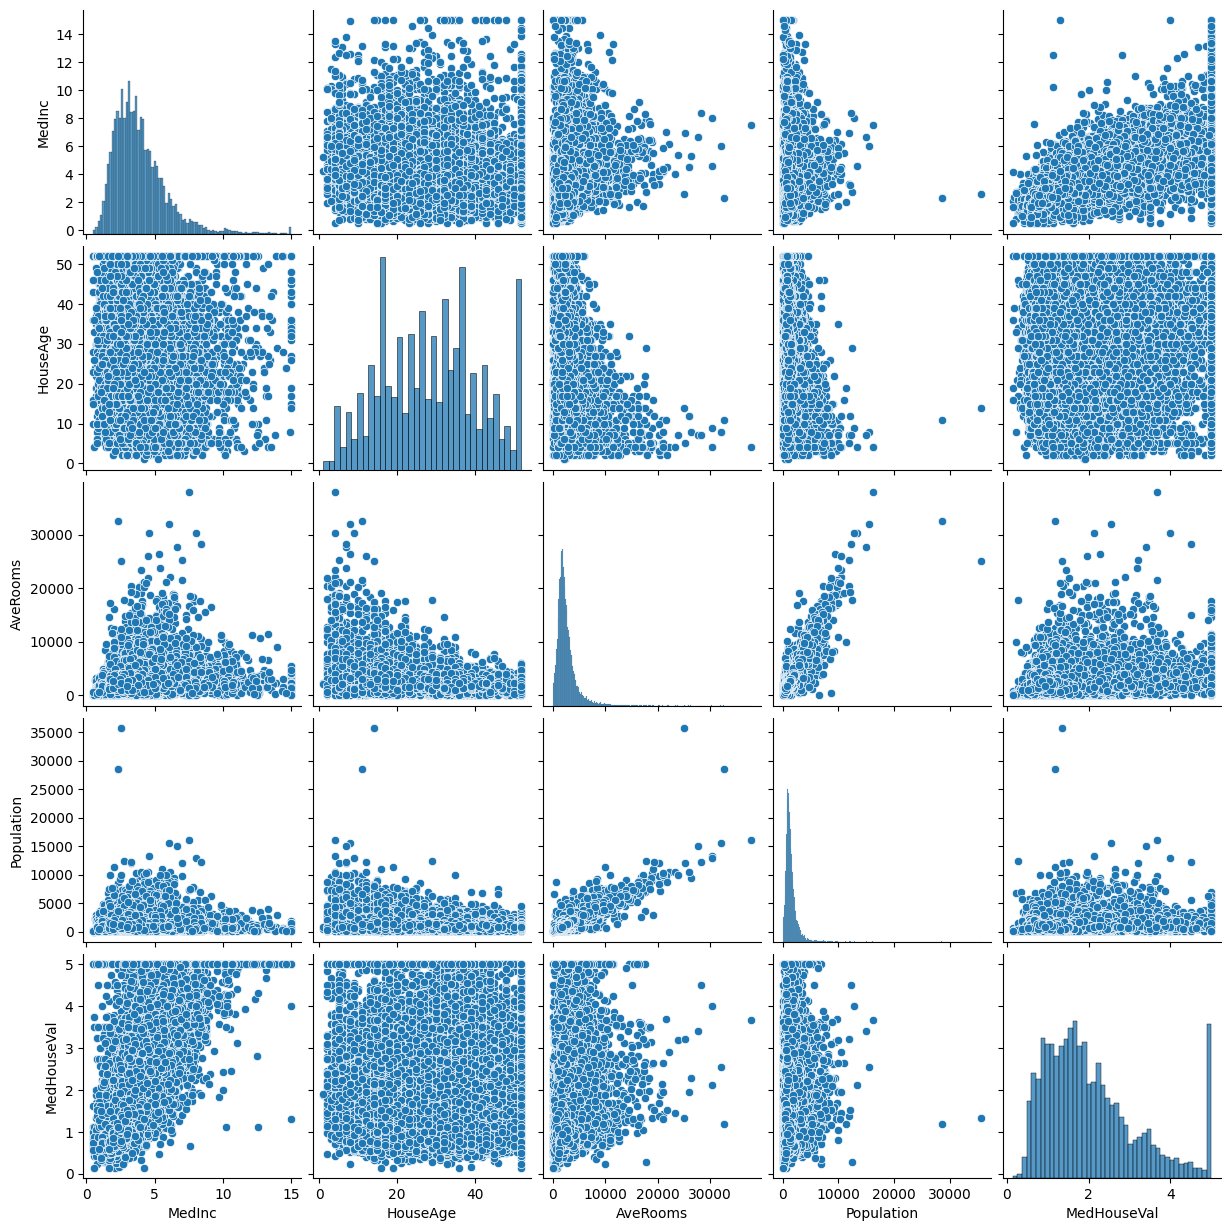

In [ ]:
#Visualizing Feature Relationships
# Pairplot for selected features
sns.pairplot(data[['MedInc', 'HouseAge', 'AveRooms', 'Population', 'MedHouseVal']])
plt.show()

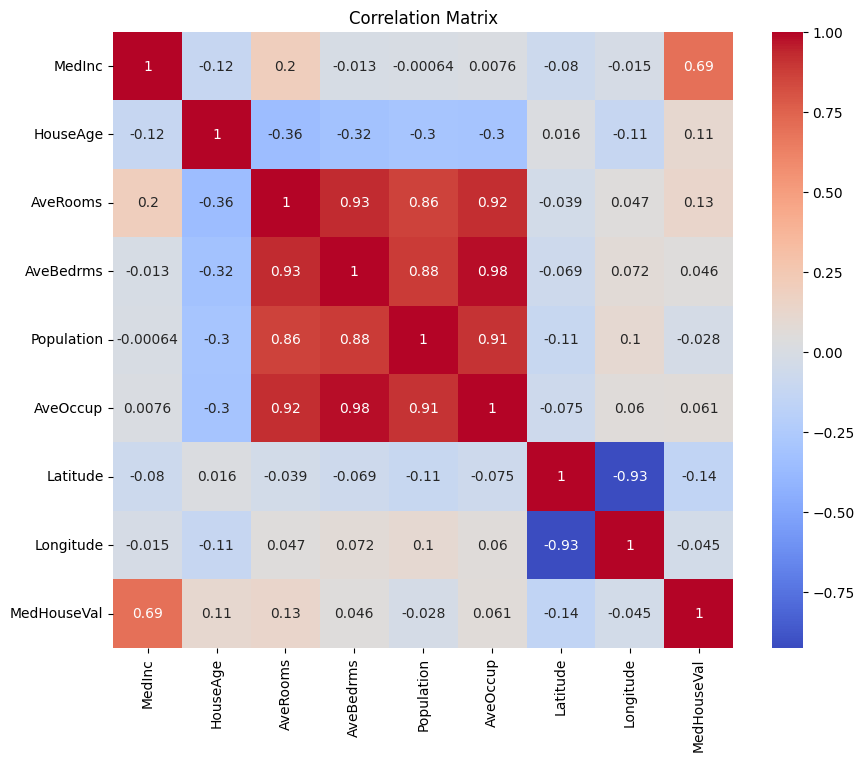

In [ ]:
# Correlation matrix
plt.figure(figsize=(10,8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [ ]:
#Step 4: Splitting the Dataset
# Features and target variable
X = data.drop('MedHouseVal', axis=1)
y = data['MedHouseVal']

# Splitting the dataset (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (13600, 8)
Testing set size: (3400, 8)


In [ ]:
#Step 5: Training the Linear Regression Model
# Initialize the Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Coefficients
print("Intercept (b0):", round(lr_model.intercept_,3))
print("Coefficients (b1, b2, ..., b8):", np.round(lr_model.coef_,4))

Intercept (b0): -36.523
Coefficients (b1, b2, ..., b8): [ 4.019e-01  1.130e-02 -1.000e-04  1.100e-03 -4.000e-04  5.000e-04
 -4.311e-01 -4.347e-01]


In [ ]:
# Predictions on the test set
y_pred = lr_model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== scikit-learn Linear Regression Evaluation ===")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R²): {r2:.4f}")

=== scikit-learn Linear Regression Evaluation ===
Mean Squared Error (MSE): 0.4635
Root Mean Squared Error (RMSE): 0.6808
Mean Absolute Error (MAE): 0.4998
R-squared (R²): 0.6636


In [ ]:
# Dummy data for prediction (same feature structure as X)
dummy_data = pd.DataFrame({
    'MedInc': [5.0, 8.0, 3.0],
    'HouseAge': [30, 10, 40],
    'AveRooms': [6.0, 5.0, 4.0],
    'AveBedrms': [1.0, 1.5, 1.0],
    'Population': [1000, 500, 2000],
    'AveOccup': [3.0, 2.5, 4.0],
    'Latitude': [34.0, 36.0, 38.0],
    'Longitude': [-120.0, -121.0, -122.0]
})

# Predictions
dummy_predictions = lr_model.predict(dummy_data)

print("=== Predictions on Dummy Data using scikit-learn Linear Regression ===")
for i, pred in enumerate(dummy_predictions, 1):
    print(f"Dummy Data {i}: Predicted MedHouseVal = {pred:.4f}")

=== Predictions on Dummy Data using scikit-learn Linear Regression ===
Dummy Data 1: Predicted MedHouseVal = 2.9743
Dummy Data 2: Predicted MedHouseVal = 3.7050
Dummy Data 3: Predicted MedHouseVal = 1.0727


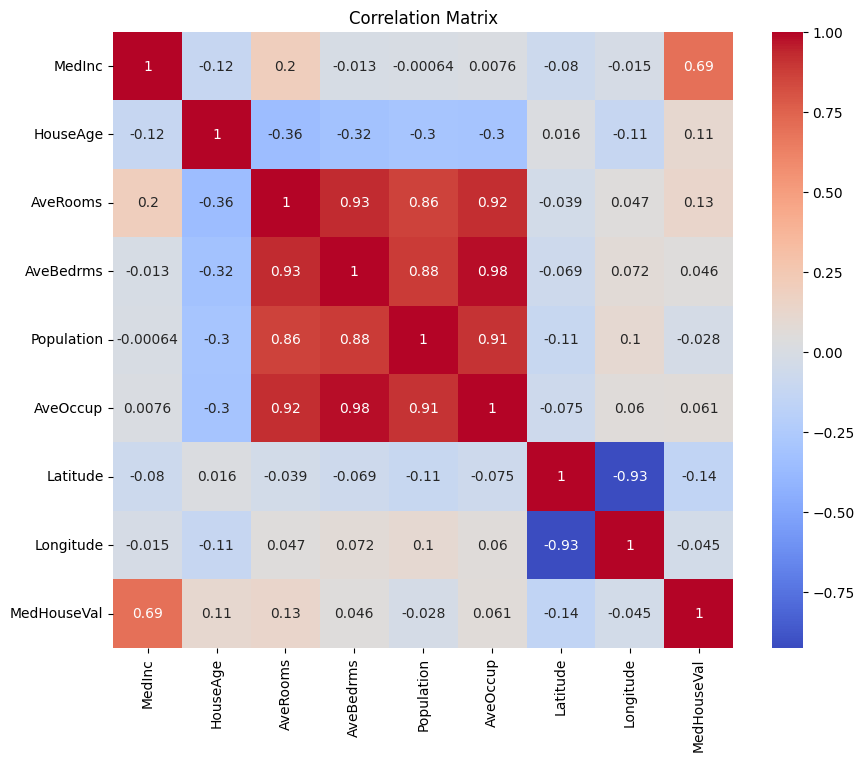

In [ ]:
# Compute the correlation matrix
corr_matrix = data.corr()

# Display the correlation matrix
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [ ]:
#We'll select features whose absolute correlation with MedHouseVal is greater than or equal to 0.5.
# Get absolute correlations with the target variable
corr_target = abs(corr_matrix['MedHouseVal'])

# Select features with correlation >= 0.05
high_corr_features = corr_target[corr_target >= 0.15].index.tolist()

# Remove the target variable from the list
high_corr_features.remove('MedHouseVal')

print("Features with high correlation (|correlation| >= 0.5) with MedHouseVal:")
print(high_corr_features)

Features with high correlation (|correlation| >= 0.5) with MedHouseVal:
['MedInc']


In [ ]:
# Define the feature matrix X and target vector y using high correlation features
X = data[high_corr_features]
y = data['MedHouseVal']

# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {X_train.shape}")
print(f"Testing set size: {X_test.shape}")

Training set size: (13600, 1)
Testing set size: (3400, 1)


In [ ]:
# Initialize the Linear Regression model
lr_model = LinearRegression()

# Train the model on the scaled training data
lr_model.fit(X_train, y_train)

# Display the model's intercept and coefficients
print(f"Intercept (b0): {lr_model.intercept_}")
print(f"Coefficients (b1, b2, b3): {lr_model.coef_}")

Intercept (b0): 0.45238285506641684
Coefficients (b1, b2, b3): [0.41669936]


In [ ]:
# Predict on the test set
y_pred = lr_model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\n=== Linear Regression Model Evaluation ===")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R²): {r2:.4f}")


=== Linear Regression Model Evaluation ===
Mean Squared Error (MSE): 0.6920
Root Mean Squared Error (RMSE): 0.8319
Mean Absolute Error (MAE): 0.6216
R-squared (R²): 0.4978
